# Phase 2: Feature Engineering for Churn Prediction

In Phase 1 I cleaned the data and grouped customers with RFM. Now I want to **predict which customers will stop buying**.

To do this fairly, I split time into two parts:
- **Before the cutoff date (observation period):** I build all customer features from this data only.
- **After the cutoff date (next 90 days):** I only use this to check whether each customer bought again. This becomes the label.

**Churn = 1** means the customer made **no purchase** in the 90 days after the cutoff.

Why not just use the RFM table from Phase 1? Because those values were calculated using all the data up to December 2011. If I used them to predict the future, the model would already be "looking at the answer", which is called **data leakage**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

## Loading the cleaned data
- I load the cleaned transactions saved at the end of Phase 1, so I don't need to clean the Excel file again.

In [2]:
df = pd.read_parquet("../data/processed/clean_sales.parquet")
print(df.shape)
print("From:", df['InvoiceDate'].min())
print("To:  ", df['InvoiceDate'].max())

(776594, 9)
From: 2009-12-01 07:45:00
To:   2011-12-09 12:50:00


## Choosing the cutoff date
- The data ends on 9 December 2011, so the last full day is the 9th and the day after is 10 December.
- I go back 90 days from 10 December to get the cutoff date. That way the 90-day label window uses all the remaining data.

In [3]:
WINDOW_DAYS = 90

data_end = df['InvoiceDate'].max().normalize() + pd.Timedelta(days=1)   # 10 Dec 2011, 00:00
CUTOFF = data_end - pd.Timedelta(days=WINDOW_DAYS)

before_cutoff = df[df['InvoiceDate'] < CUTOFF]
after_cutoff = df[(df['InvoiceDate'] >= CUTOFF) & (df['InvoiceDate'] < data_end)]

print("Cutoff date:", CUTOFF.date())
print("Observation period:", before_cutoff['InvoiceDate'].min().date(), "to", before_cutoff['InvoiceDate'].max().date())
print("Label window:      ", after_cutoff['InvoiceDate'].min().date(), "to", after_cutoff['InvoiceDate'].max().date())

Cutoff date: 2011-09-11
Observation period: 2009-12-01 to 2011-09-09
Label window:       2011-09-11 to 2011-12-09


## Building customer features
I wrote one function, `build_features()`, that creates all features for every customer using **only data before a given date**.
I made it a function because I need it twice: once for training (at the cutoff) and once for the Streamlit app (at the end of the data).

| Feature | What it means |
|---|---|
| Recency | Days since the customer's last order |
| Frequency | Number of orders |
| Monetary | Total money spent |
| Tenure | Days since the customer's first order |
| AvgOrderValue | Average money spent per order |
| AvgBasketSize | Average number of items per order |
| AvgDaysBetweenOrders | Average gap between orders (for one-time buyers I use their tenure, since they haven't come back in that time) |
| IsOneTimeBuyer | 1 if they ordered only once |
| Orders_Last90 | Orders in the 90 days before the date, to show if they are still active |
| UniqueProducts | Number of different products bought |
| Q4_Share | Share of spending in October to December (seasonal buyers) |
| IsUK | 1 if the customer is from the UK |

In [4]:
def build_features(data, as_of):
    """Build one row of features per customer, using only orders before `as_of`."""
    data = data[data['InvoiceDate'] < as_of]

    # One row per order first, so order-level averages are correct
    orders = (data.groupby(['Customer ID', 'Invoice'])
                  .agg(OrderDate=('InvoiceDate', 'min'),
                       OrderValue=('Revenue', 'sum'),
                       Items=('Quantity', 'sum'))
                  .reset_index())

    cust = orders.groupby('Customer ID').agg(
        FirstOrder=('OrderDate', 'min'),
        LastOrder=('OrderDate', 'max'),
        Frequency=('Invoice', 'nunique'),
        Monetary=('OrderValue', 'sum'),
        AvgOrderValue=('OrderValue', 'mean'),
        AvgBasketSize=('Items', 'mean')
    )

    cust['Recency'] = (as_of - cust['LastOrder']).dt.days
    cust['Tenure'] = (as_of - cust['FirstOrder']).dt.days

    active_days = (cust['LastOrder'] - cust['FirstOrder']).dt.days
    cust['AvgDaysBetweenOrders'] = np.where(cust['Frequency'] > 1,
                                            active_days / (cust['Frequency'] - 1),
                                            cust['Tenure'])
    cust['IsOneTimeBuyer'] = (cust['Frequency'] == 1).astype(int)

    recent = orders[orders['OrderDate'] >= as_of - pd.Timedelta(days=90)]
    cust['Orders_Last90'] = (recent.groupby('Customer ID')['Invoice'].nunique()
                                   .reindex(cust.index, fill_value=0))

    cust['UniqueProducts'] = data.groupby('Customer ID')['StockCode'].nunique()

    q4_revenue = (data[data['InvoiceDate'].dt.month.isin([10, 11, 12])]
                      .groupby('Customer ID')['Revenue'].sum()
                      .reindex(cust.index, fill_value=0))
    cust['Q4_Share'] = q4_revenue / cust['Monetary']

    main_country = data.groupby('Customer ID')['Country'].agg(lambda x: x.mode()[0])
    cust['IsUK'] = (main_country == 'United Kingdom').astype(int)

    return cust.drop(columns=['FirstOrder', 'LastOrder']).reset_index()

In [5]:
features = build_features(df, CUTOFF)
print(features.shape)
features.head()

(5256, 13)


,Customer ID,Frequency,Monetary,AvgOrderValue,AvgBasketSize,Recency,Tenure,AvgDaysBetweenOrders,IsOneTimeBuyer,Orders_Last90,UniqueProducts,Q4_Share,IsUK
0,12346,2,169.36,84.680,12.000000,439,557,118.0,0,0,24,0.000000,1
1,12347,6,3402.39,567.065,349.833333,39,314,54.8,0,1,107,0.388938,0
2,12348,4,1388.40,347.100,622.000000,158,348,63.0,0,0,24,0.470182,0
3,12349,2,2221.14,1110.570,495.500000,317,499,181.0,0,0,89,0.518932,0
4,12350,1,294.40,294.400,196.000000,220,220,220.0,1,0,16,0.000000,0


## Creating the churn label
- I find every customer who bought at least once in the 90 days after the cutoff.
- Customers in my feature table who are **not** in that list get Churn = 1.
- Customers who bought for the first time after the cutoff are not included, because I have no history to build their features from.

In [6]:
returned_customers = after_cutoff['Customer ID'].unique()
features['Churn'] = (~features['Customer ID'].isin(returned_customers)).astype(int)

print("Customers in training table:", len(features))
print("New customers after cutoff (not included):",
      len(set(returned_customers) - set(features['Customer ID'])))

Customers in training table: 5256
New customers after cutoff (not included): 596


## Checking the result
- No missing values
- Recency and Tenure are never negative, and Recency is never bigger than Tenure
- Every customer appears only once

In [7]:
print("Missing values:", features.isna().sum().sum())
print("Negative Recency:", (features['Recency'] < 0).sum())
print("Recency > Tenure:", (features['Recency'] > features['Tenure']).sum())
print("Duplicate customers:", features['Customer ID'].duplicated().sum())

Missing values: 0
Negative Recency: 0
Recency > Tenure: 0
Duplicate customers: 0


# EDA on the features

## Churn balance
- First I check how many customers churned. If one class is much smaller, accuracy alone would be misleading, and I will need `class_weight='balanced'` in Phase 4.

       Customers  Percent
Churn                    
0           2288     43.5
1           2968     56.5


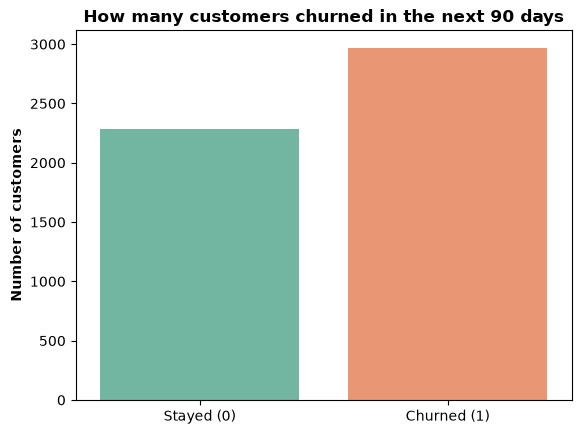

In [8]:
churn_counts = features['Churn'].value_counts().sort_index()
churn_pct = features['Churn'].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({'Customers': churn_counts, 'Percent': churn_pct.round(1)}))

ax = sns.countplot(x='Churn', data=features, hue='Churn', palette='Set2', legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Stayed (0)', 'Churned (1)'])
plt.title('How many customers churned in the next 90 days', fontweight='bold')
plt.xlabel('')
plt.ylabel('Number of customers', fontweight='bold')
plt.show()


### Insights:
- 56.5% of customers (2,968) churned and 43.5% (2,288) stayed, so the classes are fairly balanced. I don't need oversampling, but I will judge models with ROC-AUC and F1, because a model that always predicts "churn" would already get 56.5% accuracy.
- The 90-day window (September to December) is the busiest season, so many customers come back to buy Christmas stock. Churn would probably look higher in a quieter period.

## How skewed are the features?
- In Phase 1 Frequency and Monetary were very skewed. I check the same for the new features.

In [9]:
num_cols = ['Recency', 'Frequency', 'Monetary', 'Tenure', 'AvgOrderValue', 'AvgBasketSize',
            'AvgDaysBetweenOrders', 'Orders_Last90', 'UniqueProducts', 'Q4_Share']

features[num_cols].skew().sort_values(ascending=False).round(2)

AvgBasketSize           51.20
Monetary                24.21
AvgOrderValue           14.35
Frequency               10.49
Orders_Last90            9.14
UniqueProducts           6.12
AvgDaysBetweenOrders     1.35
Q4_Share                 1.03
Recency                  0.67
Tenure                  -0.63
dtype: float64

### Insights:
- AvgBasketSize (51.2), Monetary (24.2), AvgOrderValue (14.4) and Frequency (10.5) are extremely skewed, because a few wholesale customers place very large orders. Recency and Tenure are only mildly skewed.
- I will use np.log1p on the skewed features inside the model pipeline in Phase 4.

## Do churned customers look different?
- I compared each feature for customers who stayed and customers who churned. I used a log scale because the values are skewed.

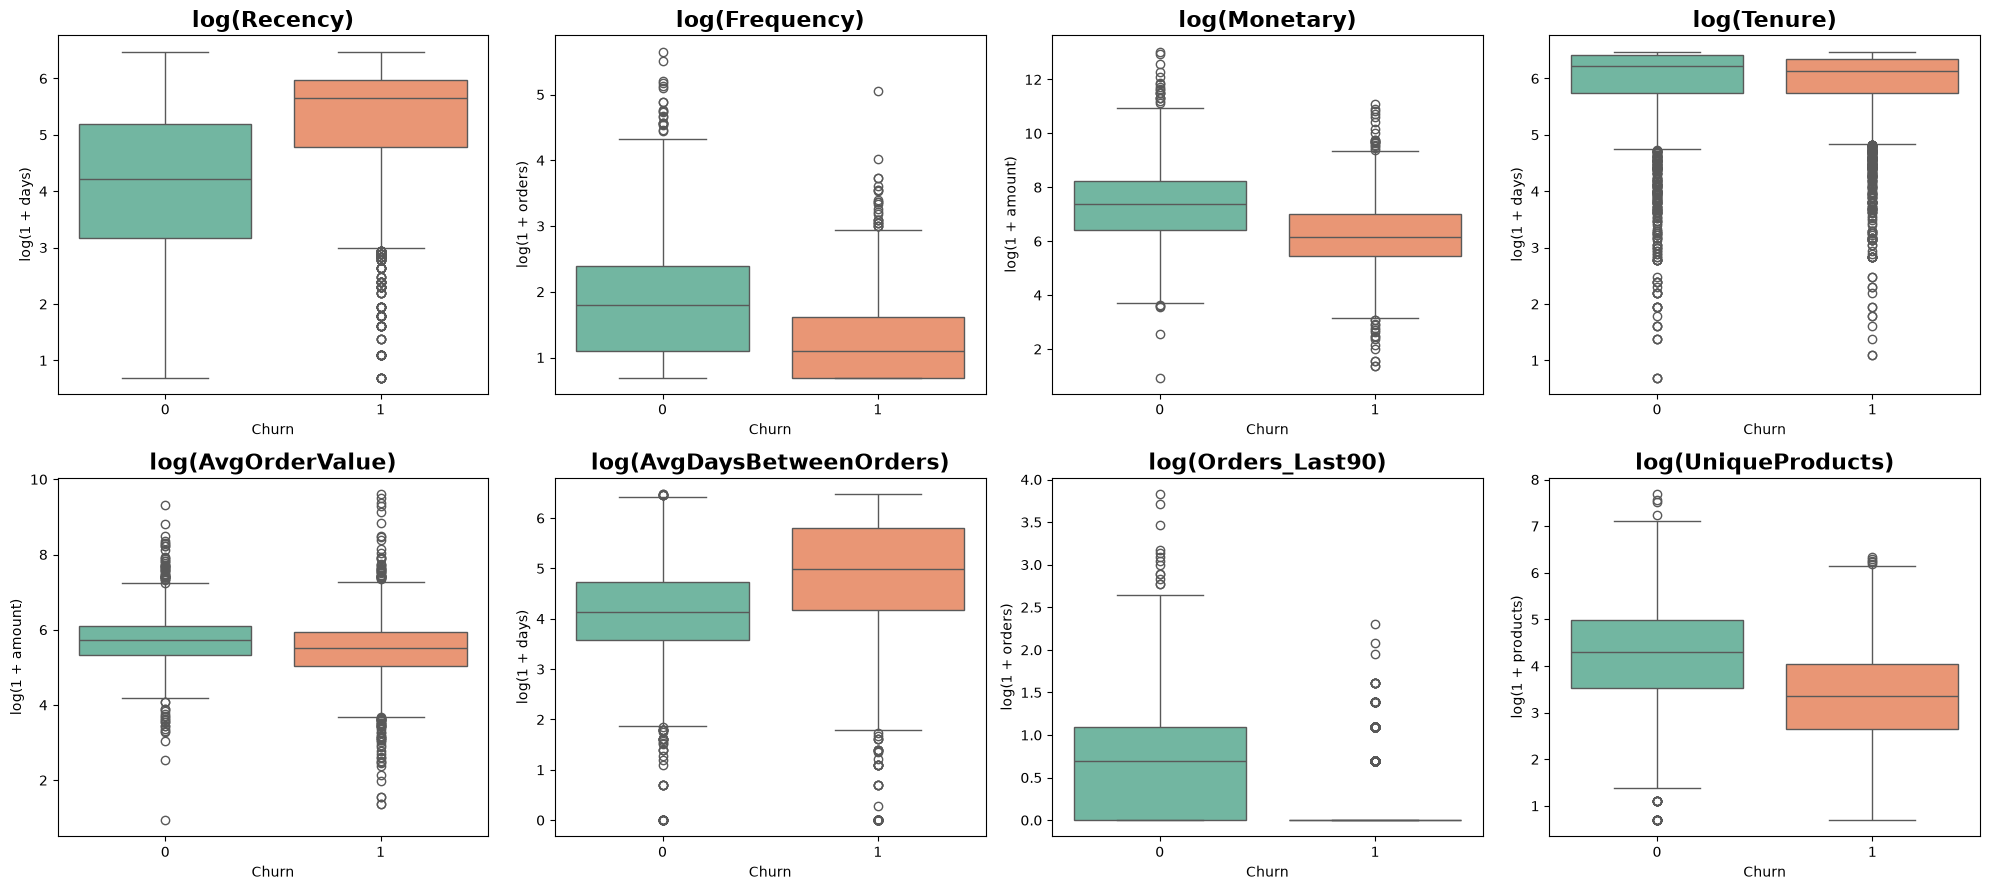

In [10]:
plot_cols = ['Recency', 'Frequency', 'Monetary', 'Tenure',
             'AvgOrderValue', 'AvgDaysBetweenOrders', 'Orders_Last90', 'UniqueProducts']
units_cols = {
    'Recency': 'days',
    'Frequency': 'orders',
    'Monetary': 'amount',
    'Tenure': 'days',
    'AvgOrderValue': 'amount',
    'AvgDaysBetweenOrders': 'days',
    'Orders_Last90': 'orders',
    'UniqueProducts': 'products',
}
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.flat, plot_cols):
    sns.boxplot(x='Churn', y=np.log1p(features[col]), data=features,
                hue='Churn', palette='Set2', legend=False, ax=ax)
    ax.set_title(f'log({col})', fontweight='bold', fontsize=16)
    ax.set_xlabel('Churn')
    ax.set_ylabel(f'log(1 + {units_cols[col]})')
plt.tight_layout()
plt.show()

### Insights:
- Recency shows the biggest difference: churned customers last bought about 280 days before the cutoff, compared with about 65 days for customers who stayed.
- Churned customers placed almost no orders in the 90 days before the cutoff and bought fewer different products than customers who stayed.
- Customers who stayed placed more orders (about 5 vs 2), spent more (about £1,600 vs £500) and ordered more often (about every 60 days vs every 145 days).
- Tenure and AvgOrderValue look almost the same in both groups, so how long someone has been a customer, or how much they spend per order, says little about churn on its own.

In [11]:
print(features.groupby('IsOneTimeBuyer')['Churn'].mean().rename('Churn rate').round(3))
print()
print(features.groupby('IsUK')['Churn'].mean().rename('Churn rate').round(3))

IsOneTimeBuyer
0    0.466
1    0.795
Name: Churn rate, dtype: float64

IsUK
0    0.532
1    0.568
Name: Churn rate, dtype: float64


### Insights:
- One-time buyers churn much more: 79.5% compared with 46.6% for repeat buyers.
- Getting a customer to place a second order is a key way to keep them.
- UK customers churn slightly more than non-UK customers (56.8% vs 53.2%), but the difference is small, so country is a weak signal.

## Which features are most related to churn?
- I used Spearman correlation again, because it works better for skewed data.
- A positive value means a higher feature value goes with more churn, and a negative value means less churn.

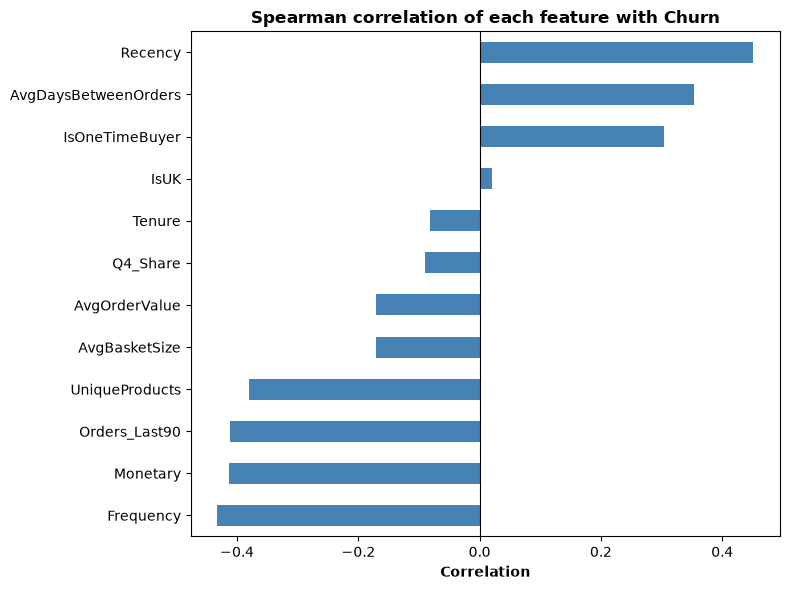

In [12]:
corr_with_churn = (features[num_cols + ['IsOneTimeBuyer', 'IsUK', 'Churn']]
                   .corr(method='spearman')['Churn']
                   .drop('Churn')
                   .sort_values())

corr_with_churn.plot(kind='barh', figsize=(8, 6), color='steelblue')
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Spearman correlation of each feature with Churn', fontweight='bold')
plt.xlabel('Correlation', fontweight='bold')
plt.tight_layout()
plt.show()

### Insights:
- Strongest link to more churn: Recency (+0.45), then AvgDaysBetweenOrders (+0.35) and IsOneTimeBuyer (+0.30).
- Strongest link to less churn: Frequency (−0.43), Monetary (−0.41), Orders_Last90 (−0.41) and UniqueProducts (−0.38).
- IsUK (+0.02), Tenure (−0.08) and Q4_Share (−0.09) are close to zero, so they are weak on their own.
- I will keep them, because they may still help in combination with other features.

## Are some features too similar to each other?
- If two features are almost the same (very high correlation), they give the model the same information twice.
- Tree models (Random Forest, XGBoost) handle this fine. For Logistic Regression I will use regularisation in Phase 4.

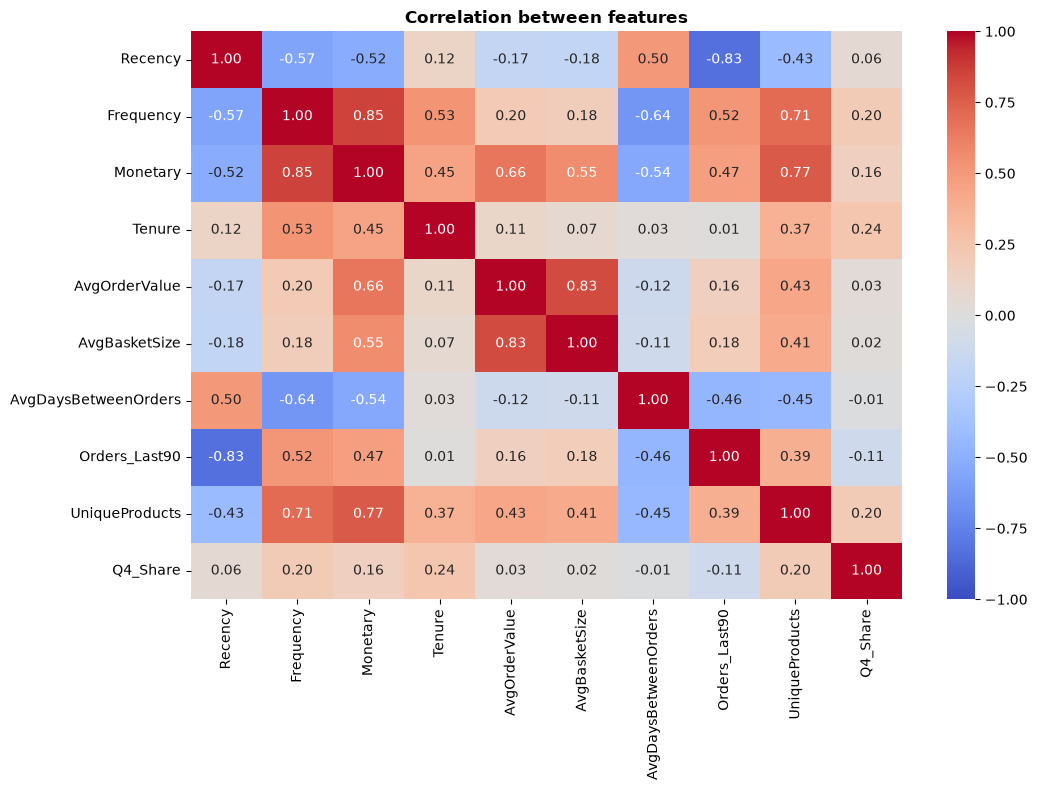

In [13]:
plt.figure(figsize=(11, 8))
sns.heatmap(features[num_cols].corr(method='spearman'), annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between features', fontweight='bold')
plt.tight_layout()
plt.show()

### Insights:
- Several pairs are highly correlated: Frequency and Monetary (0.85), AvgOrderValue and AvgBasketSize (0.83), Recency and Orders_Last90 (−0.83), and Monetary and UniqueProducts (0.77).
- These pairs give the model similar information. Tree models handle this well.
- For Logistic Regression I will use regularisation, and I will check feature importance in Phase 6 before deciding whether to drop any feature.

# Features for the Streamlit app
- The training table describes customers as they were in September 2011. For the app, I want to predict churn for customers **today** (the end of the data), so I build the same features again using all the data up to 10 December 2011.
- This table has no Churn column, because that future hasn't happened yet. The trained model will predict it.

In [14]:
current_features = build_features(df, data_end)
print(current_features.shape)
current_features.head()

(5852, 13)


,Customer ID,Frequency,Monetary,AvgOrderValue,AvgBasketSize,Recency,Tenure,AvgDaysBetweenOrders,IsOneTimeBuyer,Orders_Last90,UniqueProducts,Q4_Share,IsUK
0,12346,2,169.36,84.68000,12.000000,529,647,118.000000,0,0,24,0.000000,1
1,12347,8,4921.53,615.19125,370.875000,2,404,57.428571,0,2,126,0.577556,0
2,12348,5,1658.40,331.68000,540.800000,75,438,90.500000,0,1,24,0.393632,0
3,12349,3,3678.69,1226.23000,540.333333,18,589,285.000000,0,1,137,0.709538,0
4,12350,1,294.40,294.40000,196.000000,310,310,310.000000,1,0,16,0.000000,0


## Saving the results

In [15]:
features.to_parquet("../data/processed/churn_train.parquet", index=False)
current_features.to_parquet("../data/processed/churn_current.parquet", index=False)

print("Saved training table:", features.shape)
print("Saved current table: ", current_features.shape)

Saved training table: (5256, 14)
Saved current table:  (5852, 13)


## Summary
- I picked a cutoff date 90 days before the end of the data, built features from before it and created the churn label from after it, so there is no data leakage.
- I created 12 features per customer, including new ones beyond RFM like tenure, order gaps and recent activity.
- 56.5% of customers churned, so the classes are fairly balanced.
- Recency, Frequency, Monetary and recent activity are the strongest churn signals, and one-time buyers churn far more than repeat buyers (79.5% vs 46.6%).
- Several features are highly skewed and some are strongly correlated with each other, which I will handle in the Phase 4 pipeline.
- Next, in Phase 3, I will cluster customers, and in Phase 4 I will train the churn models on `churn_train.parquet`.